# Minimal spatial TV–TV proof of concept

**Question:** can spatial image-TV weights improve joint reconstruction and motion estimation?

One moving phantom, one alpha shortlist, one frozen map, three fresh noise samples.
The reviewed gain is small. The strict local split remains rejected.

This notebook displays saved results. The computation commands at the end are commented out;
run them individually when you want to reproduce or continue. Full details: `docs/model.md` and `docs/status.md`.


In [1]:
from pathlib import Path


import json
import subprocess
import sys
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
while not (ROOT / "scripts/run.py").is_file():
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook from the project directory.")
    ROOT = ROOT.parent

def run(action, *arguments):
    subprocess.run([sys.executable, str(ROOT / "scripts/run.py"), action, *map(str, arguments)],
                   cwd=ROOT, check=True)

def current_report():
    pointer = json.loads((ROOT / "results/proof_of_concept/latest.json").read_text())
    out = Path(pointer["output_directory"])
    return out, json.loads((out / "summary.json").read_text())

print("Project:", ROOT)


Project: /home/tunterbe/projects/tvtv-dyadic-numerics


## 1. Restore the reviewed computations

The importer checks source, observations, initial states and settings. It reuses 27 completed
solves without starting a new one. Adjust `HANDOFF` if the ZIP is in another folder.
If the ZIP is unavailable, preparation generates inputs; existing results are left in place.


In [2]:
HANDOFF = Path.home() / "Downloads/tvtv-handoff-2026-10-07.zip"
if HANDOFF.is_file():
    run("import-handoff", HANDOFF)
else:
    run("prepare")
    print("No handoff found at", HANDOFF, "— generated/reused inputs only.")
run("report")
OUT, report = current_report()


{
  "output_directory": "/home/tunterbe/projects/tvtv-dyadic-numerics/results/proof_of_concept/b0cf0d6238311fce",
  "imported_completed": 27,
  "new_solves": 0,
  "completed_solves": 27,
  "planned_solves": 27
}
{
  "output_directory": "/home/tunterbe/projects/tvtv-dyadic-numerics/results/proof_of_concept/b0cf0d6238311fce",
  "completed_solves": 27,
  "planned_solves": 27,
  "validation_complete": true,
  "spatial_wins": 3,
  "mean_relative_gain": 0.012026585287627567
}
Local selection: {'top_left': 0.001, 'top_right': 0.001, 'bottom_left': 0.000875, 'bottom_right': 0.000875} ; strict split accepted: False
compare: seed=20260930; loss gain=0.830%
validate: seed=202610071; loss gain=0.823%
validate: seed=202610072; loss gain=1.195%
validate: seed=202610073; loss gain=1.590%


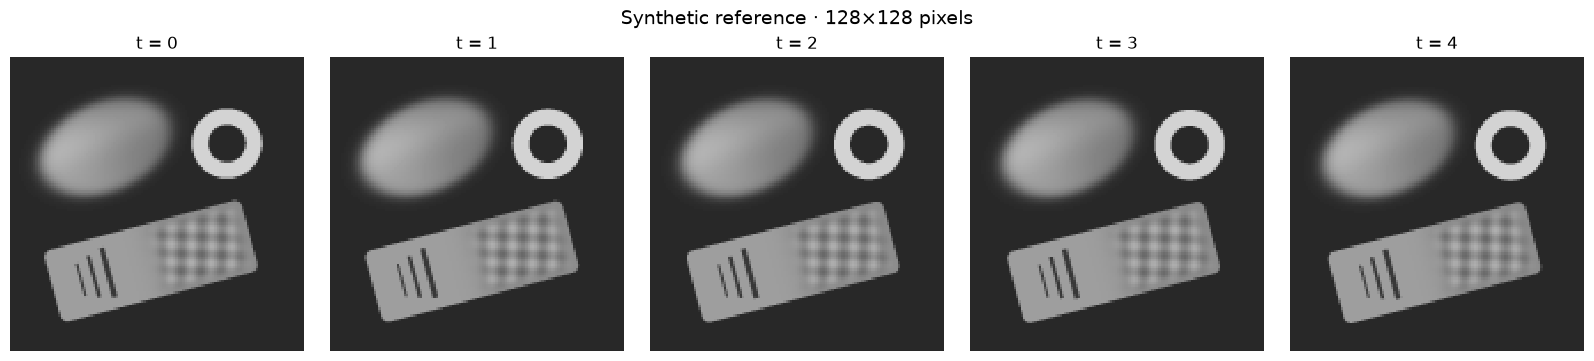

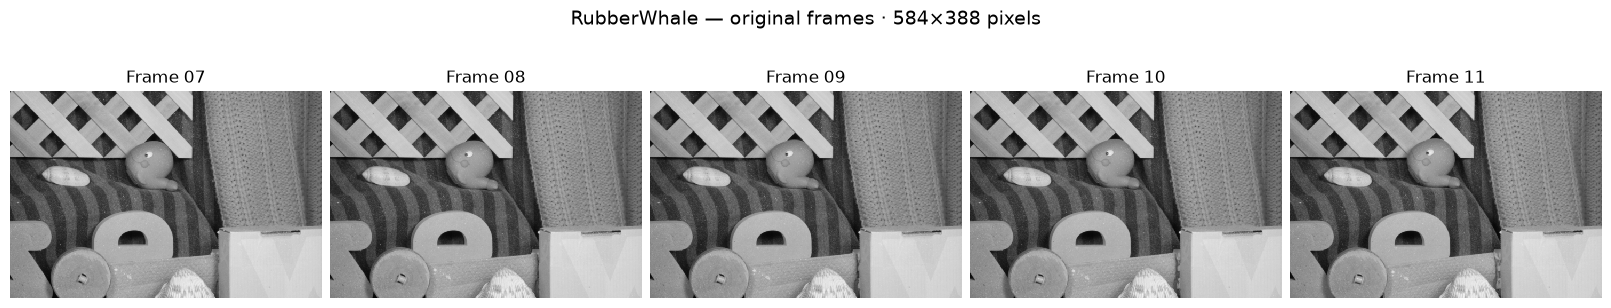

In [7]:
import io
import json
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np

# Load the exact synthetic reference used by the current experiment.
settings = json.loads(
    (ROOT / "configs/proof_of_concept.json").read_text()
)["data"]

synthetic_path = OUT / "inputs" / f"seed-{settings['design_seed']}.npz"
with np.load(synthetic_path, allow_pickle=False) as saved:
    synthetic_reference = saved["reference"].copy()
    synthetic_times = saved["times"].copy()

# Reuse cached RubberWhale frames, or download the five needed frames.
frame_numbers = list(range(7, 12))
filenames = [f"frame{k:02d}.png" for k in frame_numbers]
old_cache = ROOT / "results/minimal/source/RubberWhale"
real_cache = ROOT / "data/reference/RubberWhale"

if all((old_cache / name).is_file() for name in filenames):
    real_cache = old_cache

if not all((real_cache / name).is_file() for name in filenames):
    local_zip = ROOT / "results/minimal/source/other-gray-allframes.zip"

    if local_zip.is_file():
        archive = zipfile.ZipFile(local_zip)
    else:
        url = (
            "https://vision.middlebury.edu/flow/data/comp/zip/"
            "other-gray-allframes.zip"
        )
        print("Downloading the Middlebury archive once (about 12 MB)...")
        with urllib.request.urlopen(url, timeout=30) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))

    real_cache.mkdir(parents=True, exist_ok=True)
    with archive:
        for name in filenames:
            path = real_cache / name
            if not path.is_file():
                path.write_bytes(
                    archive.read(f"other-data-gray/RubberWhale/{name}")
                )

rubberwhale_reference = np.stack([
    plt.imread(real_cache / name) for name in filenames
])

# Display both sequences using the same grayscale range.
sequences = [
    (
        "Synthetic reference",
        synthetic_reference,
        [f"t = {t:g}" for t in synthetic_times],
    ),
    (
        "RubberWhale — original frames",
        rubberwhale_reference,
        [f"Frame {k:02d}" for k in frame_numbers],
    ),
]

for title, frames, labels in sequences:
    fig, axes = plt.subplots(
        1, len(frames),
        figsize=(16, 3.5),
        squeeze=False,
        constrained_layout=True,
    )
    fig.suptitle(
        f"{title} · {frames.shape[2]}×{frames.shape[1]} pixels",
        fontsize=14,
    )
    for ax, frame, label in zip(axes[0], frames, labels):
        ax.imshow(
            frame, cmap="gray", vmin=0, vmax=1,
            interpolation="nearest",
        )
        ax.set_title(label)
        ax.axis("off")

    plt.show()

## 2. The example and the map

Five 128×128 frames; sigma=0.1; beta=0.0125; kappa=1.
The image starts at the noisy observation; the motion starts at an observation-only translation fit.
The four full-time spatial crops selected alpha=0.001 on the top half and alpha=0.000875 on the bottom half.


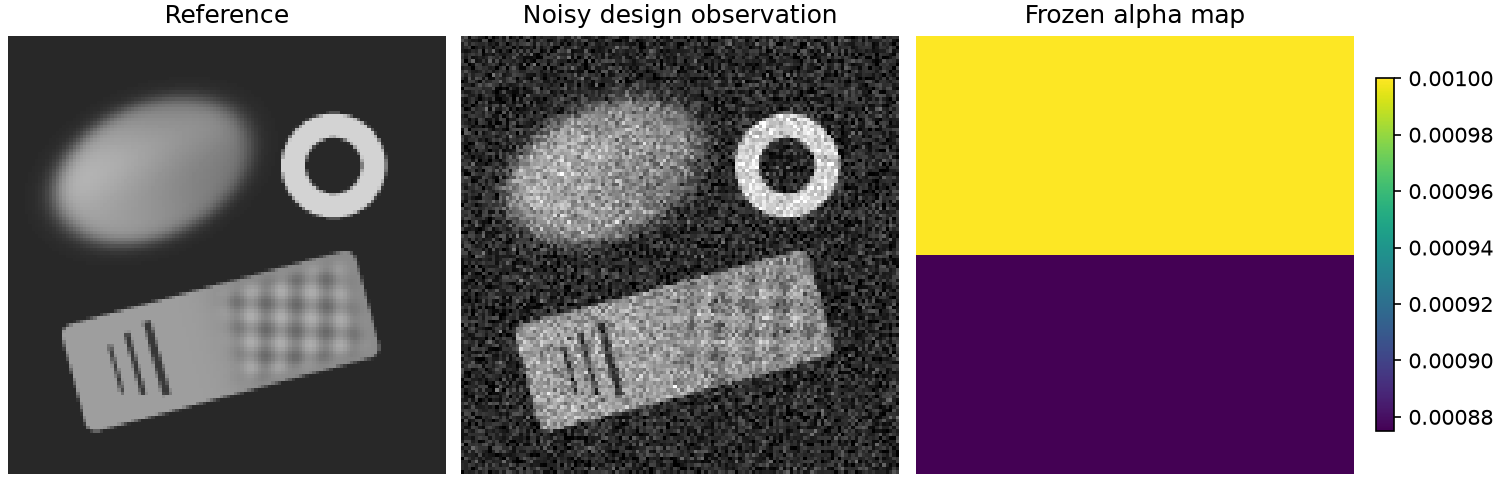

In [3]:
display(Image(filename=str(OUT / "preview.png")))


## 3. Full-sequence comparisons

The design pair uses a fixed alpha=0.000875 constant control at tighter tolerances.
Each fresh-noise comparison tests three constants at those same settings and compares the frozen
map with the best of the three. Reference images are used to evaluate the image-only 3/2 loss.


| Observation | Constant loss | Spatial loss | Relative gain |
|---|---:|---:|---:|
| compare / 20260930 | 0.007707352 | 0.007643402 | 0.830% |
| validate / 202610071 | 0.007643506 | 0.007580603 | 0.823% |
| validate / 202610072 | 0.007801311 | 0.007708078 | 1.195% |
| validate / 202610073 | 0.007442811 | 0.007324475 | 1.590% |

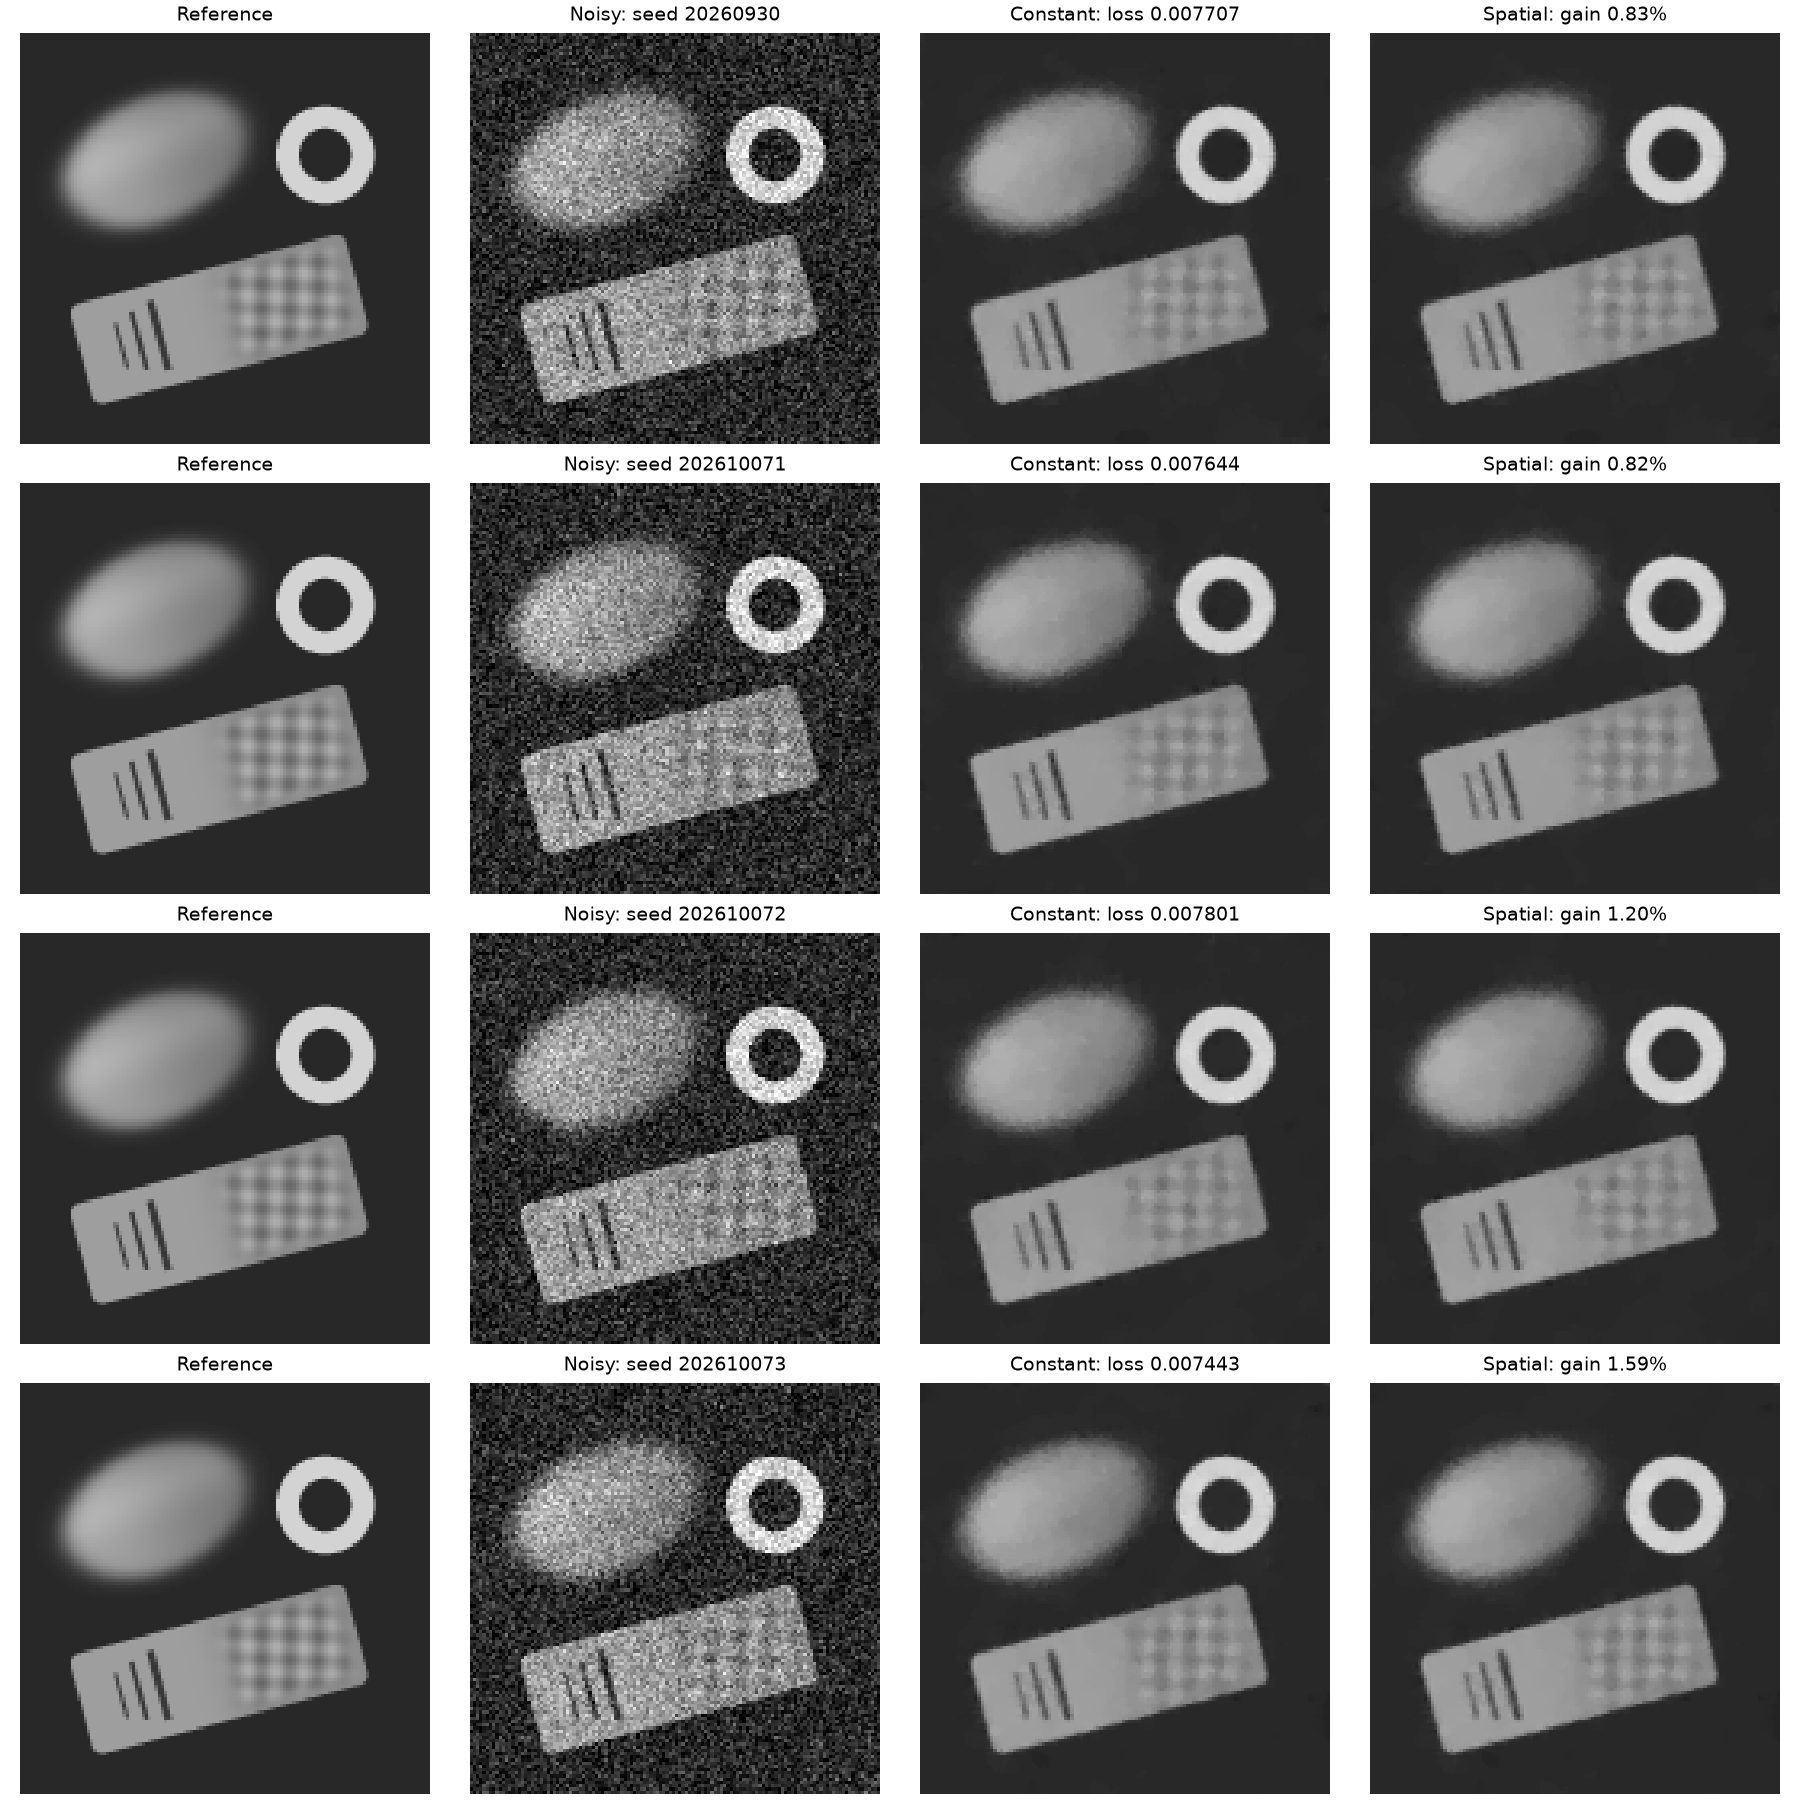

Completed solves: 27 / 27


In [4]:
lines = ["| Observation | Constant loss | Spatial loss | Relative gain |",
         "|---|---:|---:|---:|"]
for pair in report["comparisons"]:
    label = f"{pair['stage']} / {pair['seed']}"
    if pair["complete"]:
        lines.append(f"| {label} | {pair['constant_loss']:.9f} | {pair['spatial_loss']:.9f} | {100*pair['relative_gain']:.3f}% |")
    else:
        lines.append(f"| {label} | pending | pending | pending |")
display(Markdown("\n".join(lines)))
if (OUT / "comparison.png").is_file():
    display(Image(filename=str(OUT / "comparison.png")))
print("Completed solves:", report["completed_solves"], "/", report["planned_solves"])


## 4. Local selection and the strict split

A global reconstruction with the proposed map can improve even when independent crop costs reject
the split. These are separate questions. The current example demonstrates the usefulness of spatial
weights; it does not establish successful automatic refinement.


In [5]:
learning = report["learning"]
print("Selected alphas:", learning["selected_alphas"])
print("Frozen map matches local selection:", learning["frozen_map_matches_selection"])
if learning["complete"]:
    display(Markdown(f"""| Cost | Image loss |
|---|---:|
| Parent global | {learning['parent_global_loss']:.9f} |
| Crops at parent alpha | {learning['children_parent_alpha_loss']:.9f} |
| Crops at selected alphas | {learning['children_selected_loss']:.9f} |

**Strict split accepted:** {learning['strict_split_accepted']}"""))
else:
    print("Local selection is not complete.")


Selected alphas: {'top_left': 0.001, 'top_right': 0.001, 'bottom_left': 0.000875, 'bottom_right': 0.000875}
Frozen map matches local selection: True


| Cost | Image loss |
|---|---:|
| Parent global | 0.007726162 |
| Crops at parent alpha | 0.007914797 |
| Crops at selected alphas | 0.007850382 |

**Strict split accepted:** False

## 5. Explicit computation commands

Uncomment one command and run that cell when you want it. Repeated commands reuse completed results
and resume compatible partial checkpoints. Each solve runs in an isolated process with a hard time
limit. A batch stops at its first unresolved candidate. Opening/running this notebook as supplied
starts no search or reconstruction.


In [6]:
# run("smoke")
# run("learn", "--seconds", 60, "--budget-minutes", 15)
# run("compare", "--budget-minutes", 20)
# run("validate", "--budget-minutes", 90)
# run("report")  # refresh figures/metrics, with no solves


## 6. Save the current experiment for review or another computer

The export contains input arrays, compatible saved results, available checkpoints, configuration and
source. The path is printed. It performs no new solves. The committed `evidence/` summaries remain a
small record of the reviewed October 7 computations.


In [ ]:
# run("export")


The measured fresh-noise image-loss gains are about 0.8–1.6%, with much smaller RMSE gains and essentially
unchanged texture RMSE. Three samples on one scene do not show statistical significance or generalization.
Before adding real data or deeper partitions, discuss how to increase the global gain while addressing
crop-boundary costs in the refinement rule.
